In [8]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ---------------------------------------------------------------- style
MODELS = ["DPOT", "DISCO", "HFluxNO"]  # legend and draw order
# colorcet glasbey_bw indices 41, 85, 68 (same as Fig. 3)
COLORS = {"HFluxNO": "#3715ff", "DPOT": "#ff2747", "DISCO": "#00653c"}
MARKERS = {"HFluxNO": "o", "DPOT": "s", "DISCO": "^"}
OFFSETS = {"DPOT": -0.24, "DISCO": 0.0, "HFluxNO": 0.24}  # within-group x offsets
COND_DX = 0.065  # lower / upper condition drawn at xm -/+ COND_DX


def _darken(hexc: str, f: float = 0.6) -> tuple:
    r, g, b = mpl.colors.to_rgb(hexc)
    return (r * f, g * f, b * f)


def _fill(cond: str) -> str:
    """Return the marker fill of a condition: filled in distribution, hollow for
    shock-dominated initial conditions."""
    if cond == "ID":
        return "full"
    if cond == "shock IC":
        return "none"
    raise ValueError(f"Unknown condition {cond!r}; expected 'ID' or 'shock IC'.")


# (axis label, family key, lower condition, upper condition)
# "ID" is drawn filled and "shock IC" hollow.
GROUPS = [
    ("1D cubic", "1D cubic", "ID", "shock IC"),
    ("Shallow water", "1D shallow water", "ID", "shock IC"),
    ("Viscous Burgers", "1D viscous Burgers", "ID", "shock IC"),
    ("2D cubic", "2D cubic", "ID", "shock IC"),
    ("2D Euler", "2D Euler", "ID", "shock IC"),
]

METRICS = [("l2", r"Rel. $\ell^2$"), ("linf", r"Rel. $\ell^\infty$")]

RC = {
    "font.family": "serif",
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "ytick.minor.width": 0.4,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}


def plot_accuracy(
    results: dict, out: str | None = None, width: float = 5.5, height: float = 2.9
):
    """Draw the figure and optionally save it (any matplotlib format)."""
    xs = [float(i) for i in range(len(GROUPS))]
    with mpl.rc_context(RC):
        fig, axes = plt.subplots(
            2, 1, figsize=(width, height), sharex=True, gridspec_kw={"hspace": 0.12}
        )
        for ax, (metric, ylabel) in zip(axes, METRICS):
            ax.set_yscale("log")
            vals = [
                v[metric][0]
                for fam in results.values()
                for cond in fam.values()
                for v in cond.values()
                if metric in v
            ]
            if vals:
                ax.set_ylim(min(vals) / 1.6, max(vals) * 1.6)
            ax.set_ylabel(ylabel)
            ax.yaxis.grid(True, which="major", color="0.88", lw=0.5)
            ax.set_axisbelow(True)
            for spine in ("top", "right"):
                ax.spines[spine].set_visible(False)
            ax.tick_params(axis="x", length=0)

            for x, (_, fam, lo, hi) in zip(xs, GROUPS):
                fam_res = results.get(fam, {})
                drawn = False
                for model in MODELS:
                    xm = x + OFFSETS[model]
                    c = COLORS[model]
                    pts = {}
                    for cond in (lo, hi):
                        v = fam_res.get(cond, {}).get(model, {}).get(metric)
                        if v is not None:
                            pts[cond] = v
                    xpos = {lo: xm - COND_DX, hi: xm + COND_DX}
                    for cond, (m, sd) in pts.items():
                        fs = _fill(cond)
                        # whisker behind the marker, in a darker shade of the
                        # model colour; a whisker longer than the marker radius
                        # shows on both sides, a shorter one is hidden (std
                        # below ~5% of the mean, see caption)
                        ax.errorbar(
                            xpos[cond],
                            m,
                            yerr=sd,
                            fmt="none",
                            ecolor=_darken(c),
                            elinewidth=0.7,
                            capsize=1.5,
                            capthick=0.7,
                            zorder=3,
                        )
                        ax.plot(
                            xpos[cond],
                            m,
                            marker=MARKERS[model],
                            ms=5.5,
                            mfc=c if fs != "none" else "white",
                            mec=c,
                            mew=0.9,
                            ls="none",
                            zorder=4,
                        )
                        drawn = True
                if not drawn and ax is axes[0]:
                    ax.text(
                        x,
                        0.5,
                        "pending",
                        ha="center",
                        va="center",
                        fontsize=7,
                        color="0.5",
                        style="italic",
                        transform=ax.get_xaxis_transform(),
                    )

        axes[-1].set_xticks(xs)
        axes[-1].set_xticklabels([g[0] for g in GROUPS])
        axes[-1].set_xlim(xs[0] - 0.6, xs[-1] + 0.6)

        # legend: model identity (colour + shape) and condition (fill)
        handles = [
            Line2D(
                [],
                [],
                marker=MARKERS[m],
                color=COLORS[m],
                mfc=COLORS[m],
                ls="none",
                ms=5,
                label=m,
            )
            for m in ["HFluxNO", "DPOT", "DISCO"]
        ]
        handles += [
            Line2D(
                [],
                [],
                marker="o",
                color="0.3",
                mfc="0.3",
                ls="none",
                ms=5,
                label="In Distribution",
            ),
        ]
        handles.append(
            Line2D(
                [],
                [],
                marker="o",
                color="0.3",
                mfc="white",
                ls="none",
                ms=5,
                label="Shock IC",
            )
        )
        axes[0].legend(
            handles=handles,
            ncol=len(handles),
            loc="lower center",
            bbox_to_anchor=(0.5, 1.0),
            frameon=False,
            handletextpad=0.4,
            columnspacing=1.2,
        )

        if out:
            fig.savefig(out, bbox_inches="tight", pad_inches=0.02, dpi=600)
        return fig

In [9]:
results = {
    "1D cubic": {
        "ID": {  # Table 1
            "DPOT": {"l2": (1.36e-1, 3.12e-3), "linf": (6.78e-1, 9.65e-3)},
            "DISCO": {"l2": (8.22e-2, 5.58e-3), "linf": (4.55e-1, 3.12e-2)},
            "HFluxNO": {"l2": (5.21e-2, 2.15e-3), "linf": (3.68e-1, 1.56e-2)},
        },
        "shock IC": {  # Table 2, "1D cubic" block
            "DPOT": {"l2": (1.58e-1, 3.95e-3), "linf": (8.23e-1, 3.82e-2)},
            "DISCO": {"l2": (8.58e-2, 5.69e-3), "linf": (4.73e-1, 2.63e-2)},
            "HFluxNO": {"l2": (6.68e-2, 1.69e-3), "linf": (4.35e-1, 8.96e-3)},
        },
    },
    "1D shallow water": {
        "ID": {
            "DPOT": {"l2": (1.05e-1, 3.66e-3), "linf": (4.63e-1, 1.00e-2)},
            "DISCO": {"l2": (1.11e-1, 5.82e-3), "linf": (4.45e-1, 2.01e-2)},
            "HFluxNO": {"l2": (7.55e-2, 1.26e-3), "linf": (3.98e-1, 4.21e-3)},
        },
        "shock IC": {
            "DPOT": {"l2": (7.54e-2, 1.32e-3), "linf": (3.30e-1, 3.80e-3)},
            "DISCO": {"l2": (1.04e-1, 4.36e-3), "linf": (3.87e-1, 1.17e-2)},
            "HFluxNO": {"l2": (6.41e-2, 2.7e-4), "linf": (3.16e-1, 7.2e-4)},
        },
    },
    "1D viscous Burgers": {
        "ID": {
            "DPOT": {"l2": (4.66e-2, 1.07e-3), "linf": (1.56e-1, 4.39e-3)},
            "DISCO": {"l2": (6.56e-2, 3.35e-2), "linf": (3.43e-1, 2.34e-1)},
            "HFluxNO": {"l2": (1.72e-2, 2.35e-4), "linf": (6.46e-2, 6.51e-4)},
        },
        "shock IC": {
            "DPOT": {"l2": (4.50e-2, 3.19e-3), "linf": (1.78e-1, 1.17e-2)},
            "DISCO": {"l2": (4.53e-2, 1.41e-2), "linf": (2.41e-1, 1.25e-1)},
            "HFluxNO": {"l2": (2.21e-2, 5.04e-4), "linf": (9.99e-2, 9.47e-4)},
        },
    },
    "2D cubic": {
        "ID": {
            "DPOT": {"l2": (2.19e-1, 1.49e-2), "linf": (7.84e-1, 4.33e-2)},
            "DISCO": {"l2": (3.68e-2, 4.29e-3), "linf": (1.40e-1, 1.11e-2)},
            "HFluxNO": {"l2": (1.31e-2, 6.48e-4), "linf": (6.38e-2, 3.44e-3)},
        },
        "shock IC": {
            "DPOT": {"l2": (8.12e-1, 2.64e-2), "linf": (1.69e0, 1.16e-1)},
            "DISCO": {"l2": (2.04e-1, 1.14e-2), "linf": (6.79e-1, 3.47e-2)},
            "HFluxNO": {"l2": (1.76e-1, 2.43e-2), "linf": (5.65e-1, 7.46e-2)},
        },
    },
    "2D Euler": {  # 20-step rollout; single-step numbers in full_results_tables
        "ID": {
            "DPOT": {"l2": (2.23e-1, 7.97e-3), "linf": (7.13e-1, 2.14e-2)},
            "DISCO": {"l2": (1.27e-1, 1.12e-2), "linf": (5.45e-1, 3.82e-2)},
            "HFluxNO": {"l2": (3.94e-2, 8.40e-4), "linf": (3.27e-1, 6.30e-3)},
        },
        "shock IC": {
            "DPOT": {"l2": (1.77e-1, 6.98e-3), "linf": (7.81e-1, 4.43e-2)},
            "DISCO": {"l2": (1.05e-1, 1.27e-2), "linf": (4.97e-1, 6.11e-2)},
            "HFluxNO": {"l2": (2.68e-2, 3.72e-4), "linf": (2.37e-1, 3.51e-3)},
        },
    },
}

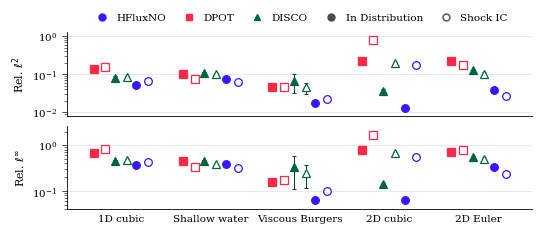

In [10]:
plot_accuracy(results, out="../../figures/fig2.pdf", width=6.0, height=2.3)

In [32]:
import json
from pathlib import Path

import numpy as np
from context_flux_no.simulations.pde.godunov_1d import (
    buckley_leverett_max_speed,
    buckley_leverett_speed,
)
from jaxtyping import Float


# ------------------------------------------------- unseen-flux sweeps (1D cubic models)
# Written by evaluate_cubic_unseen_flux.ipynb, one file per test set.
UNSEEN_FLUX_DIR = Path("../../data/analysis/unseen_flux")
# name in this notebook -> key in the result files
RESULT_KEYS = {"HFluxNO": "HyperFluxFNOLocal", "DPOT": "DPOT", "DISCO": "DISCO"}
IDENTITY_KEY = "Identity"
# (key in the result files, axis label)
UNSEEN_FLUX_METRICS = {
    "l2": ("l2_rollout", r"20-step rel. $\ell^2$ error"),
    "linf": ("l_inf_rollout", r"20-step rel. $\ell^\infty$ error"),
}
TRAINING_COEFFICIENT_MAX = 1.0  # cubic coefficients are drawn from U[-1, 1]


def sine_wave_speed(u: Float[np.ndarray, " n"], b: float) -> Float[np.ndarray, " n"]:
    """Wave speed f'(u) = cos(b u) of the rescaled sine flux f(u) = sin(b u) / |b|,
    at the amplitude a' = 1."""
    return np.cos(b * u)


def buckley_leverett_wave_speed(
    u: Float[np.ndarray, " n"], log10_mobility_ratio: float
) -> Float[np.ndarray, " n"]:
    """Wave speed of the Buckley-Leverett flux in the variable u = 2 s - 1, scaled to a
    maximum of 1 as in `generate_unseen_flux_1d.py` at the amplitude a' = 1."""
    mobility_ratio = 10.0**log10_mobility_ratio
    return buckley_leverett_speed(
        (1.0 + u) / 2.0, mobility_ratio
    ) / buckley_leverett_max_speed(mobility_ratio)


# One entry per panel: title, axis label of the shape parameter, wave speed as a
# function of (u, shape parameter), and per bin the tick label, the result file and the
# shape parameter at the bin center.
UNSEEN_FLUX_PANELS = [
    (
        "Sine flux, GRF data",
        r"$|b|$",
        sine_wave_speed,
        [
            ("(0,1]", "sine_rescaled_0-1_grf", 0.5),
            ("(1,2]", "sine_rescaled_1-2_grf", 1.5),
            ("(2,3]", "sine_rescaled_2-3_grf", 2.5),
            ("(3,4]", "sine_rescaled_3-4_grf", 3.5),
        ],
    ),
    (
        "Sine flux, step data",
        r"$|b|$",
        sine_wave_speed,
        [
            ("(0,1]", "sine_rescaled_0-1_step_min2", 0.5),
            ("(1,2]", "sine_rescaled_1-2_step_min2", 1.5),
            ("(2,3]", "sine_rescaled_2-3_step_min2", 2.5),
            ("(3,4]", "sine_rescaled_3-4_step_min2", 3.5),
        ],
    ),
    (
        "B–L flux, step data",
        r"$|\log_{10} M|$",
        buckley_leverett_wave_speed,
        [
            ("(0,0.3]", "buckley_leverett_0-0.3_step_min2", 0.15),
            ("(0.3,0.7]", "buckley_leverett_0.3-0.7_step_min2", 0.5),
            ("(0.7,1]", "buckley_leverett_0.7-1_step_min2", 0.85),
        ],
    ),
]


def load_unseen_flux_result(name: str) -> dict:
    """Read the result file of one test set and check that it holds every model and
    the identity baseline."""
    path = UNSEEN_FLUX_DIR / f"{name}.json"
    if not path.exists():
        raise FileNotFoundError(f"No result file {path}.")
    with open(path) as f:
        result = json.load(f)
    missing = [
        key
        for key in (*RESULT_KEYS.values(), IDENTITY_KEY)
        if key not in result["results"]
    ]
    if missing:
        raise KeyError(f"{path} has no results for {missing}.")
    return result


def seed_mean_and_std(result: dict, key: str, metric: str) -> tuple[float, float]:
    """Mean and standard deviation over the training seeds of one model."""
    per_seed = [summary[metric]["mean"] for summary in result["results"][key]]
    return float(np.mean(per_seed)), float(np.std(per_seed))


def closest_training_wave_speed(
    u: Float[np.ndarray, " n"], speed: Float[np.ndarray, " n"]
) -> Float[np.ndarray, " n"]:
    """Wave speed of the cubic flux that is closest to a given wave speed.

    The wave speed of a cubic flux c1 u + c2 u^2 + c3 u^3 is the quadratic
    c1 + 2 c2 u + 3 c3 u^2, so the closest one is the least-squares quadratic on the
    samples `u`. The function raises if the fitted flux has a coefficient outside the
    training range, because the fit is then not a member of the training family.
    """
    q2, q1, q0 = np.polyfit(u, speed, 2)
    cubic_coefficients = np.array([q0, q1 / 2.0, q2 / 3.0])
    if np.any(np.abs(cubic_coefficients) > TRAINING_COEFFICIENT_MAX):
        raise ValueError(
            f"The closest cubic flux has the coefficients {cubic_coefficients}, "
            f"outside [-{TRAINING_COEFFICIENT_MAX}, {TRAINING_COEFFICIENT_MAX}]."
        )
    return np.polyval([q2, q1, q0], u)


def plot_unseen_flux(
    metric: str, out: str | None = None, width: float = 6.0, height: float = 2.7
):
    """Draw the error of the 1D cubic models against the shape of an unseen flux.

    Each panel is one sweep. The thumbnails above a panel show, per bin, the wave speed
    of the test flux at the bin center over the closest wave speed of the training
    family, on |u| <= 1.

    **Arguments:**

    - `metric`: `"l2"` or `"linf"`, the 20-step rollout error to draw.
    - `out`: file to save the figure to, in any matplotlib format.
    - `width`, `height`: figure size in inches.

    **Returns:**

    The figure.
    """
    if metric not in UNSEEN_FLUX_METRICS:
        raise ValueError(
            f"Unknown metric {metric!r}; expected one of {list(UNSEEN_FLUX_METRICS)}."
        )
    result_metric, ylabel = UNSEEN_FLUX_METRICS[metric]
    # (panel, bin) -> {name: (mean, std)}, read before anything is drawn
    values = [
        [
            {
                name: seed_mean_and_std(result, key, result_metric)
                for name, key in (*RESULT_KEYS.items(), ("Identity", IDENTITY_KEY))
            }
            for result in (load_unseen_flux_result(s) for _, s, _ in bins)
        ]
        for _, _, _, bins in UNSEEN_FLUX_PANELS
    ]
    y_max = max(v[0] for panel in values for bin_ in panel for v in bin_.values())
    u = np.linspace(-1.0, 1.0, 401)

    with mpl.rc_context(RC):
        fig = plt.figure(figsize=(width, height))
        outer = fig.add_gridspec(
            1,
            len(UNSEEN_FLUX_PANELS),
            width_ratios=[len(bins) for *_, bins in UNSEEN_FLUX_PANELS],
            wspace=0.15,
            left=0.085,
            right=0.995,
            top=0.91,
            bottom=0.29,
        )
        first_ax = None
        for k, (title, xlabel, wave_speed, bins) in enumerate(UNSEEN_FLUX_PANELS):
            inner = outer[k].subgridspec(
                2, len(bins), height_ratios=[1, 4.2], hspace=0.12, wspace=0.25
            )
            ax = fig.add_subplot(inner[1, :], sharey=first_ax)
            first_ax = first_ax or ax
            x = np.arange(len(bins))

            ax.plot(
                x,
                [b["Identity"][0] for b in values[k]],
                color="0.45",
                ls=(0, (4, 2)),
                lw=0.9,
                marker="x",
                ms=3.5,
                zorder=2,
            )
            for model in MODELS:
                mean, std = np.array([b[model] for b in values[k]]).T
                ax.errorbar(
                    x,
                    mean,
                    yerr=std,
                    color=COLORS[model],
                    ecolor=_darken(COLORS[model]),
                    marker=MARKERS[model],
                    ms=4.5,
                    mec="white",
                    mew=0.5,
                    lw=1.1,
                    elinewidth=0.7,
                    capsize=1.5,
                    capthick=0.7,
                    zorder=3,
                )

            ax.set_xticks(x)
            ax.set_xticklabels([b[0] for b in bins])
            ax.set_xlim(-0.5, len(bins) - 0.5)
            ax.set_ylim(0.0, 1.08 * y_max)
            ax.set_xlabel(xlabel, labelpad=1)
            ax.yaxis.grid(True, which="major", color="0.88", lw=0.5)
            ax.set_axisbelow(True)
            for spine in ("top", "right"):
                ax.spines[spine].set_visible(False)
            if k == 0:
                ax.set_ylabel(ylabel)
            else:
                plt.setp(ax.get_yticklabels(), visible=False)

            for j, (_, _, shape) in enumerate(bins):
                thumb = fig.add_subplot(inner[0, j])
                speed = wave_speed(u, shape)
                thumb.axhline(0.0, color="0.85", lw=0.3)
                thumb.plot(
                    u,
                    closest_training_wave_speed(u, speed),
                    color="0.6",
                    lw=1.6,
                    solid_capstyle="round",
                )
                thumb.plot(u, speed, color="k", lw=0.7)
                thumb.set_xlim(-1.08, 1.08)
                thumb.set_ylim(-1.25, 1.25)
                thumb.set_xticks([])
                thumb.set_yticks([])
                for spine in thumb.spines.values():
                    spine.set_linewidth(0.3)
                    spine.set_color("0.7")
                if k == 0 and j == 0:
                    thumb.set_ylabel("$f'(u)$", rotation=0, labelpad=9, va="center")

            position = outer[k].get_position(fig)
            fig.text((position.x0 + position.x1) / 2, 0.955, title, ha="center")

        handles = [
            Line2D(
                [],
                [],
                color=COLORS[m],
                marker=MARKERS[m],
                ms=4.5,
                mec="white",
                mew=0.5,
                lw=1.1,
                label=m,
            )
            for m in ["HFluxNO", "DPOT", "DISCO"]
        ]
        handles.append(
            Line2D(
                [],
                [],
                color="0.45",
                ls=(0, (4, 2)),
                lw=0.9,
                marker="x",
                ms=3.5,
                label="Identity",
            )
        )
        handles.extend(
            [
                Line2D([], [], color="k", lw=0.7, label="Test $f'(u)$"),
                Line2D(
                    [], [], color="0.6", lw=1.6, label="Closest train-family $f'(u)$"
                ),
            ]
        )
        fig.legend(
            handles=handles,
            ncol=len(handles),
            loc="lower center",
            bbox_to_anchor=(0.52, 0.065),
            frameon=False,
            handlelength=2.2,
            columnspacing=1.6,
        )

        if out:
            fig.savefig(out, bbox_inches="tight", pad_inches=0.02, dpi=600)
        return fig

2026-11-18 15:29:15,857 INFO CLAW: maxp pruned
2026-11-18 15:29:15,862 INFO CLAW: cmap pruned
2026-11-18 15:29:15,862 INFO CLAW: kern dropped
2026-11-18 15:29:15,862 INFO CLAW: post pruned
2026-11-18 15:29:15,863 INFO CLAW: FFTM dropped
2026-11-18 15:29:15,864 INFO CLAW: GPOS pruned
2026-11-18 15:29:15,866 INFO CLAW: GSUB pruned
2026-11-18 15:29:15,869 INFO CLAW: glyf pruned
2026-11-18 15:29:15,869 INFO CLAW: Added gid0 to subset
2026-11-18 15:29:15,870 INFO CLAW: Added first four glyphs to subset
2026-11-18 15:29:15,870 INFO CLAW: Closing glyph list over 'GSUB': 9 glyphs before
2026-11-18 15:29:15,870 INFO CLAW: Glyph names: ['.notdef', '.null', 'M', 'b', 'f', 'nonmarkingreturn', 'space', 'u', 'uni2113']
2026-11-18 15:29:15,871 INFO CLAW: Glyph IDs:   [0, 1, 2, 3, 48, 69, 73, 88, 2738]
2026-11-18 15:29:15,872 INFO CLAW: Closed glyph list over 'GSUB': 10 glyphs after
2026-11-18 15:29:15,872 INFO CLAW: Glyph names: ['.notdef', '.null', 'M', 'b', 'f', 'nonmarkingreturn', 'space', 'u', 'u

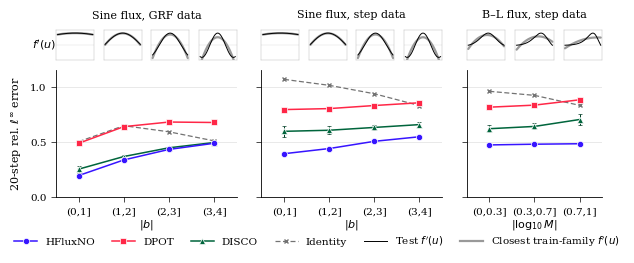

In [33]:
plot_unseen_flux("l2", out="../../figures/unseen_flux_l2.pdf")
plot_unseen_flux("linf", out="../../figures/unseen_flux_linf.pdf")